# Polynomial Regression

## Objective
Predict salary based on years of experience using Polynomial Regression.

## Concepts
- Linear Regression
- Polynomial Features
- Polynomial Regression
- Underfitting and Overfitting
- Model Evaluation

## Dataset
- Feature: YearsExperience
- Target: Salary

# 1 - Import Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2 - Data set

In [6]:
data = {
    "YearsExperience": [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15,
        16, 17, 18, 19, 20
    ],
    "Salary": [
        25, 28, 32, 38, 45,
        53, 62, 72, 83, 95,
        108, 122, 137, 153, 170,
        188, 207, 227, 248, 270
    ]
}

df = pd.DataFrame(data)

df.head()

,YearsExperience,Salary
0,1,25
1,2,28
2,3,32
3,4,38
4,5,45


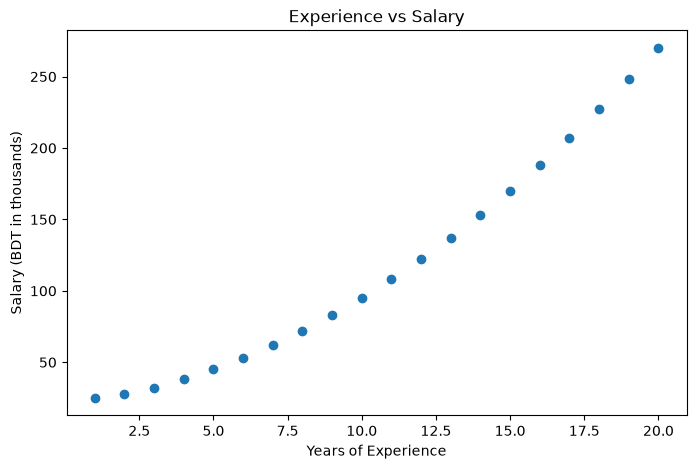

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["YearsExperience"],
    df["Salary"]
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary (BDT in thousands)")
plt.title("Experience vs Salary")

plt.show()

In [8]:
X = df[["YearsExperience"]]
y = df["Salary"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (20, 1)
Target shape: (20,)


# 3 - Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


# 4 - Linear Regression Baseline

In [10]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, linear_predictions))

Linear Regression R2: 0.9115390727073808


# 5 - Polynomial Features

In [11]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:")
print(X_train.head())

print("\nPolynomial features:")
print(X_train_poly[:5])

Original features:
    YearsExperience
8                 9
5                 6
11               12
3                 4
18               19

Polynomial features:
[[  1.   9.  81.]
 [  1.   6.  36.]
 [  1.  12. 144.]
 [  1.   4.  16.]
 [  1.  19. 361.]]


In [12]:
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

poly_predictions = poly_model.predict(X_test_poly)

print("Polynomial Regression R2:", r2_score(y_test, poly_predictions))

Polynomial Regression R2: 0.9998508620175386


In [13]:
degrees = [1, 2, 3, 4, 5]

results = []

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    predictions = model.predict(X_test_poly)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results.append({
        "Degree": degree,
        "R2 Score": r2,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

results_df

,Degree,R2 Score,RMSE
0,1,0.911539,27.229309
1,2,0.999851,1.118034
2,3,0.999851,1.118034
3,4,0.999851,1.118034
4,5,0.999997,0.150218


# 6 - Results Visualization

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


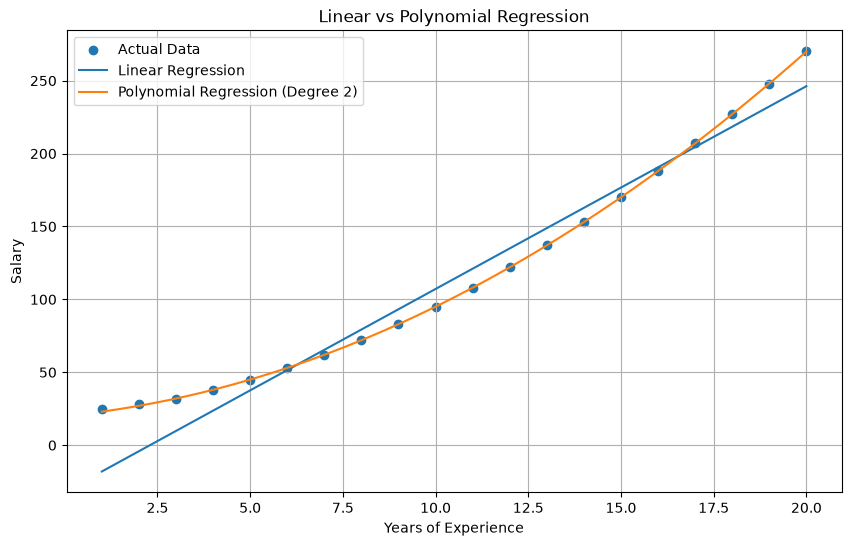

In [15]:
from sklearn.preprocessing import PolynomialFeatures
import pandas as pd
X_curve = np.linspace(
    X["YearsExperience"].min(),
    X["YearsExperience"].max(),
    200
).reshape(-1, 1)

plt.figure(figsize=(10, 6))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Linear Regression
plt.plot(
    X_curve,
    linear_model.predict(X_curve),
    label="Linear Regression"
)

# Polynomial Regression (Degree 2)
X_curve_poly = poly_model 

degree_2 = PolynomialFeatures(degree=2)
X_curve_transformed = degree_2.fit_transform(X_curve)

plt.plot(
    X_curve,
    X_curve_transformed @ poly_model.coef_ + poly_model.intercept_,
    label="Polynomial Regression (Degree 2)"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear vs Polynomial Regression")

plt.legend()
plt.grid(True)
plt.show()

# 7 - Model evaluation

In [17]:
best_degree = int(
    results_df.loc[results_df["RMSE"].idxmin(), "Degree"]
)

print("Best Degree:", best_degree)

Best Degree: 5


In [18]:
best_poly = PolynomialFeatures(degree=best_degree)

X_train_best = best_poly.fit_transform(X_train)
X_test_best = best_poly.transform(X_test)

best_model = LinearRegression()

best_model.fit(X_train_best, y_train)

best_predictions = best_model.predict(X_test_best)


In [19]:
mae = mean_absolute_error(y_test, best_predictions)

mse = mean_squared_error(y_test, best_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, best_predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.1271828081867037
MSE: 0.022565405738104914
RMSE: 0.15021786091575434
R2 Score: 0.9999973077127319


# 8 - Actual vs Predicted

In [20]:
comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": best_predictions
})

comparison["Difference"] = (
    comparison["Actual Salary"] -
    comparison["Predicted Salary"]
)

comparison

,Actual Salary,Predicted Salary,Difference
0,25,24.858645,0.141355
1,227,227.109539,-0.109539
2,188,187.982978,0.017022
3,28,27.759185,0.240815


# 9 - Saved the model

In [21]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/polynomial_model.pkl")
joblib.dump(best_poly, "models/polynomial_features.pkl")

print("Model and Polynomial Transformer Saved!")

Model and Polynomial Transformer Saved!
